# TA-05 | Klasifikasi Pengunduran Diri Karyawan (Employee Attrition) dengan Decision Tree

**Mata Praktikum:** Pembelajaran Mesin &nbsp;|&nbsp; **Modul 05:** Algoritma Decision Tree

**Nama / NIM:** [isi nama dan NIM]

**Tujuan:** membangun dua model Decision Tree (Model A tanpa batas kedalaman dan Model B yang di-*pruning*), membandingkannya, menginterpretasikan Model B, lalu menyimpannya (Joblib) untuk dipakai aplikasi web Flask.

**Dataset:** IBM HR Analytics Employee Attrition (Kaggle) · https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset

**Alur notebook:** 1) Persiapan → 2) Muat data → 3) EDA → 4) Missing values → 5) Encoding → 6) Split → 7) Model A dan B → 8) Evaluasi → 9) Visualisasi dan interpretasi → 10) Simpan model untuk Flask.

> Jalankan seluruh sel **dari atas ke bawah (Run All)**. Sel terakhir menyimpan `model/`, `metrics.json`, dan gambar di `static/img/` yang dibaca oleh `app.py`.

## 1. Persiapan Library dan Path

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

sns.set_theme(style="whitegrid")

# Notebook berada di folder notebook/, jadi root proyek adalah satu tingkat di atasnya
BASE = Path.cwd().parent
DATA_PATH = BASE / "data" / "WA_Fn-UseC_-HR-Employee-Attrition.csv"
IMG_DIR = BASE / "static" / "img"
MODEL_DIR = BASE / "model"
IMG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

# Fitur yang dipakai (dipilih agar formulir web tetap ringkas)
NUM_COLS = ["Age", "MonthlyIncome", "DistanceFromHome", "JobLevel", "YearsAtCompany",
            "TotalWorkingYears", "NumCompaniesWorked", "JobSatisfaction",
            "EnvironmentSatisfaction", "WorkLifeBalance", "StockOptionLevel"]
CAT_COLS = ["OverTime", "MaritalStatus", "BusinessTravel"]
LABELS = ["Bertahan", "Resign"]
print("Path data:", DATA_PATH, "| ada:", DATA_PATH.exists())

Path data: /home/claude/ta05/data/WA_Fn-UseC_-HR-Employee-Attrition.csv | ada: True


## 2. Memuat Dataset
Dataset dimuat dengan Pandas. Kolom target adalah `Attrition` (Yes = resign, No = bertahan).

In [2]:
df = pd.read_csv(DATA_PATH)
print("Ukuran data (baris, kolom):", df.shape)
df.head()

Ukuran data (baris, kolom): (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
# Kolom yang tidak informatif: nilainya konstan atau hanya ID
konstan = [c for c in df.columns if df[c].nunique() == 1]
print("Kolom konstan:", konstan, "| Kolom ID: ['EmployeeNumber']")
df.info()

Kolom konstan: ['EmployeeCount', 'Over18', 'StandardHours'] | Kolom ID: ['EmployeeNumber']
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvemen

## 3. Eksplorasi Data (EDA)

### 3.1 Distribusi variabel target
Plot ini memeriksa apakah kelas seimbang. Jika tidak seimbang, akurasi saja bisa menyesatkan, sehingga *recall* kelas Resign perlu diperhatikan.

Attrition
No     1233
Yes     237
Name: count, dtype: int64
Attrition
No     83.9 %
Yes    16.1 %
Name: count, dtype: str


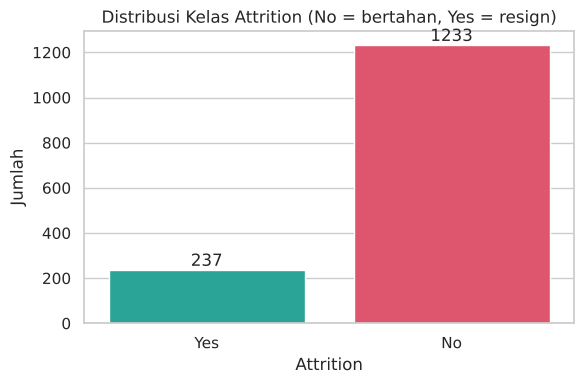

In [4]:
counts = df["Attrition"].value_counts()
print(counts)
print((counts / len(df) * 100).round(1).astype(str) + " %")

plt.figure(figsize=(6, 4))
ax = sns.countplot(x="Attrition", data=df, hue="Attrition",
                   palette=["#14b8a6", "#f43f5e"], legend=False)
for c in ax.containers:
    ax.bar_label(c)
plt.title("Distribusi Kelas Attrition (No = bertahan, Yes = resign)")
plt.xlabel("Attrition")
plt.ylabel("Jumlah")
plt.tight_layout()
plt.savefig(IMG_DIR / "target_distribution.png", dpi=150)
plt.show()

**Interpretasi:** kelas tidak seimbang, sekitar 84% karyawan bertahan dan hanya sekitar 16% resign. Karena itu evaluasi tidak boleh hanya melihat akurasi.

### 3.2 Hubungan fitur dengan target

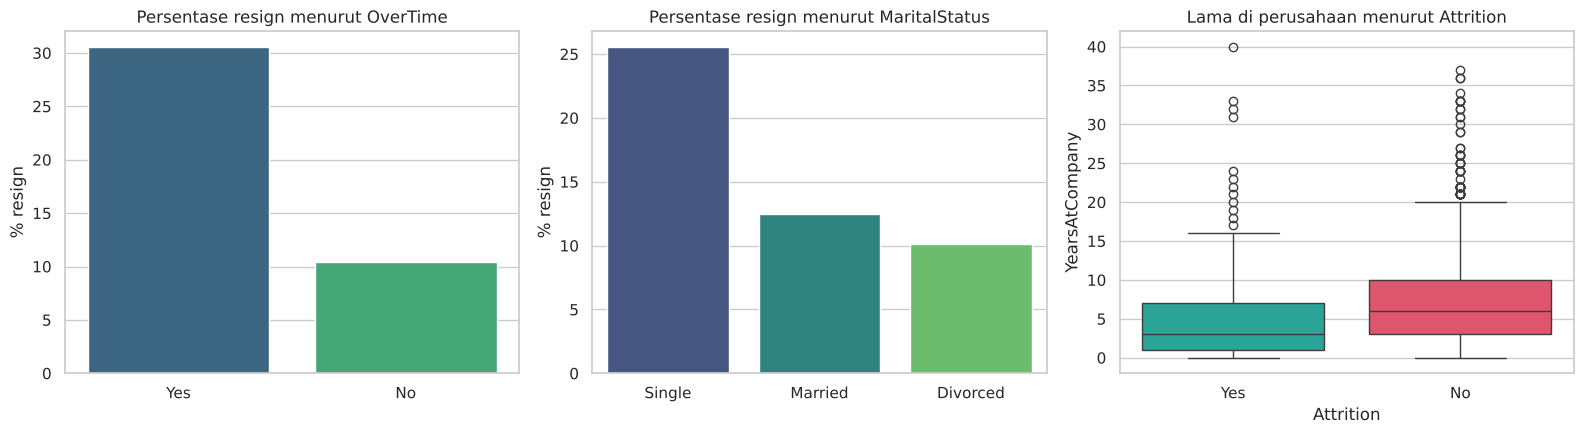

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Kategorikal: persentase resign per kategori
for ax, col in zip(axes[:2], ["OverTime", "MaritalStatus"]):
    rate = (df.groupby(col)["Attrition"].apply(lambda s: (s == "Yes").mean() * 100)
              .sort_values(ascending=False))
    sns.barplot(x=rate.index, y=rate.values, hue=rate.index, palette="viridis", legend=False, ax=ax)
    ax.set_title(f"Persentase resign menurut {col}")
    ax.set_ylabel("% resign")
    ax.set_xlabel("")

# Numerik: sebaran lama bekerja
sns.boxplot(x="Attrition", y="YearsAtCompany", data=df, hue="Attrition",
            palette=["#14b8a6", "#f43f5e"], legend=False, ax=axes[2])
axes[2].set_title("Lama di perusahaan menurut Attrition")
plt.tight_layout()
plt.show()

**Interpretasi:** persentase resign pada karyawan yang lembur (sekitar 30%) jauh lebih tinggi daripada yang tidak lembur (sekitar 10%), karyawan lajang (sekitar 25%) lebih tinggi daripada yang menikah atau cerai, dan median masa kerja yang resign lebih pendek (3 tahun dibanding 6 tahun). Pola ini nanti terlihat juga pada pohon keputusan.

## 4. Menangani Missing Values
Periksa nilai yang hilang pada fitur terpilih. Strategi: **median** untuk fitur numerik dan **modus** untuk fitur kategorikal.

In [6]:
df = df[NUM_COLS + CAT_COLS + ["Attrition"]].copy()
print("Missing values per kolom:")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().sum().sum() else "Tidak ada nilai yang hilang (total = 0)")

# Strategi tetap diterapkan agar pipeline aman bila data baru memiliki nilai kosong
for c in NUM_COLS:
    df[c] = df[c].fillna(df[c].median())
for c in CAT_COLS:
    df[c] = df[c].fillna(df[c].mode()[0])
print("Total missing setelah penanganan:", df.isna().sum().sum())

Missing values per kolom:
Tidak ada nilai yang hilang (total = 0)
Total missing setelah penanganan: 0


## 5. Encoding Fitur Kategorikal dan Pembagian Data
Fitur kategorikal (`OverTime`, `MaritalStatus`, `BusinessTravel`) diubah menjadi angka dengan **One-Hot Encoding** (`pd.get_dummies`). Target diubah menjadi 1 = Resign dan 0 = Bertahan.

In [7]:
y = (df["Attrition"] == "Yes").astype(int)
X = pd.get_dummies(df[NUM_COLS + CAT_COLS], columns=CAT_COLS, dtype=int)
print("Jumlah fitur setelah encoding:", X.shape[1])
X.head()

Jumlah fitur setelah encoding: 19


,Age,MonthlyIncome,DistanceFromHome,JobLevel,YearsAtCompany,TotalWorkingYears,NumCompaniesWorked,JobSatisfaction,EnvironmentSatisfaction,WorkLifeBalance,StockOptionLevel,OverTime_No,OverTime_Yes,MaritalStatus_Divorced,MaritalStatus_Married,MaritalStatus_Single,BusinessTravel_Non-Travel,BusinessTravel_Travel_Frequently,BusinessTravel_Travel_Rarely
0,41,5993,1,2,6,8,8,4,2,1,0,0,1,0,0,1,0,0,1
1,49,5130,8,2,10,10,1,2,3,3,1,1,0,0,1,0,0,1,0
2,37,2090,2,1,0,7,6,3,4,3,0,0,1,0,0,1,0,0,1
3,33,2909,3,1,8,8,1,3,4,3,0,0,1,0,1,0,0,1,0
4,27,3468,2,1,2,6,9,2,1,3,1,1,0,0,1,0,0,0,1


In [8]:
# stratify=y menjaga proporsi kelas yang sama pada data latih dan uji
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("Proporsi resign latih:", round(y_train.mean(), 3), "| uji:", round(y_test.mean(), 3))

Data latih: (1029, 19) | Data uji: (441, 19)
Proporsi resign latih: 0.161 | uji: 0.161


## 6. Membangun Dua Model

- **Model A (potensi overfit):** `max_depth=None`, pohon tumbuh sampai semua daun murni.
- **Model B (pruned):** `max_depth=4`, `min_samples_leaf=10` (pre-pruning) dan `class_weight="balanced"` untuk menangani kelas yang tidak seimbang.

In [9]:
model_a = DecisionTreeClassifier(max_depth=None, random_state=42)
model_b = DecisionTreeClassifier(max_depth=4, min_samples_leaf=10,
                                 class_weight="balanced", random_state=42)
model_a.fit(X_train, y_train)
model_b.fit(X_train, y_train)

print("Model A -> kedalaman:", model_a.get_depth(), "| jumlah daun:", model_a.get_n_leaves())
print("Model B -> kedalaman:", model_b.get_depth(), "| jumlah daun:", model_b.get_n_leaves())

Model A -> kedalaman: 16 | jumlah daun: 148
Model B -> kedalaman: 4 | jumlah daun: 16


## 7. Evaluasi dan Perbandingan Model A vs B

In [10]:
def evaluate(name, model):
    pred = model.predict(X_test)
    rep = classification_report(y_test, pred, target_names=LABELS, output_dict=True)
    print(f"===== {name} =====")
    print("Confusion matrix:\n", confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, target_names=LABELS))
    proba = model.predict_proba(X_test)[:, 1]
    return {
        "depth": int(model.get_depth()),
        "leaves": int(model.get_n_leaves()),
        "acc_train": round(accuracy_score(y_train, model.predict(X_train)), 4),
        "acc_test": round(accuracy_score(y_test, pred), 4),
        "auc": round(roc_auc_score(y_test, proba), 4),
        "precision_resign": round(rep["Resign"]["precision"], 4),
        "recall_resign": round(rep["Resign"]["recall"], 4),
        "f1_resign": round(rep["Resign"]["f1-score"], 4),
        "cm": confusion_matrix(y_test, pred).tolist(),
        "proba": proba,
    }

res_a = evaluate("MODEL A (tanpa batas)", model_a)
res_b = evaluate("MODEL B (pruned)", model_b)

===== MODEL A (tanpa batas) =====
Confusion matrix:
 [[313  57]
 [ 51  20]]
              precision    recall  f1-score   support

    Bertahan       0.86      0.85      0.85       370
      Resign       0.26      0.28      0.27        71

    accuracy                           0.76       441
   macro avg       0.56      0.56      0.56       441
weighted avg       0.76      0.76      0.76       441

===== MODEL B (pruned) =====
Confusion matrix:
 [[301  69]
 [ 32  39]]
              precision    recall  f1-score   support

    Bertahan       0.90      0.81      0.86       370
      Resign       0.36      0.55      0.44        71

    accuracy                           0.77       441
   macro avg       0.63      0.68      0.65       441
weighted avg       0.82      0.77      0.79       441



In [11]:
tabel = pd.DataFrame({
    "Model A (overfit)": [res_a["depth"], res_a["leaves"], res_a["acc_train"], res_a["acc_test"],
                          res_a["precision_resign"], res_a["recall_resign"], res_a["f1_resign"], res_a["auc"]],
    "Model B (pruned)":  [res_b["depth"], res_b["leaves"], res_b["acc_train"], res_b["acc_test"],
                          res_b["precision_resign"], res_b["recall_resign"], res_b["f1_resign"], res_b["auc"]],
}, index=["Kedalaman", "Jumlah daun", "Akurasi latih", "Akurasi uji",
          "Precision (Resign)", "Recall (Resign)", "F1 (Resign)", "AUC"])
tabel

,Model A (overfit),Model B (pruned)
Kedalaman,16.0000,4.0000
Jumlah daun,148.0000,16.0000
Akurasi latih,1.0000,0.8086
Akurasi uji,0.7551,0.7710
Precision (Resign),0.2597,0.3611
Recall (Resign),0.2817,0.5493
F1 (Resign),0.2703,0.4358
AUC,0.5638,0.7152


**Analisis perbandingan:**

- **Overfitting pada Model A:** akurasi data latih 100% tetapi akurasi data uji jauh lebih rendah (sekitar 75%). Model menghafal data latih, termasuk noise, sehingga gagal menggeneralisasi.
- **Model B lebih stabil:** selisih akurasi latih dan uji kecil (sekitar 4 poin), pohonnya jauh lebih sederhana (16 daun dibanding 148).
- **Kemampuan mendeteksi resign meningkat:** recall kelas Resign naik dari sekitar 0,28 menjadi 0,55 dan AUC naik dari sekitar 0,56 menjadi 0,72.
- **Kelemahan Model B:** precision kelas Resign masih rendah (sekitar 0,36), artinya banyak peringatan resign yang ternyata salah. Ini harga yang dibayar agar lebih banyak karyawan yang benar-benar resign terdeteksi.
- **Kesimpulan:** Model B dipilih untuk aplikasi web.

## 8. Visualisasi dan Interpretasi Model B

### 8.1 Confusion matrix Model A dan B

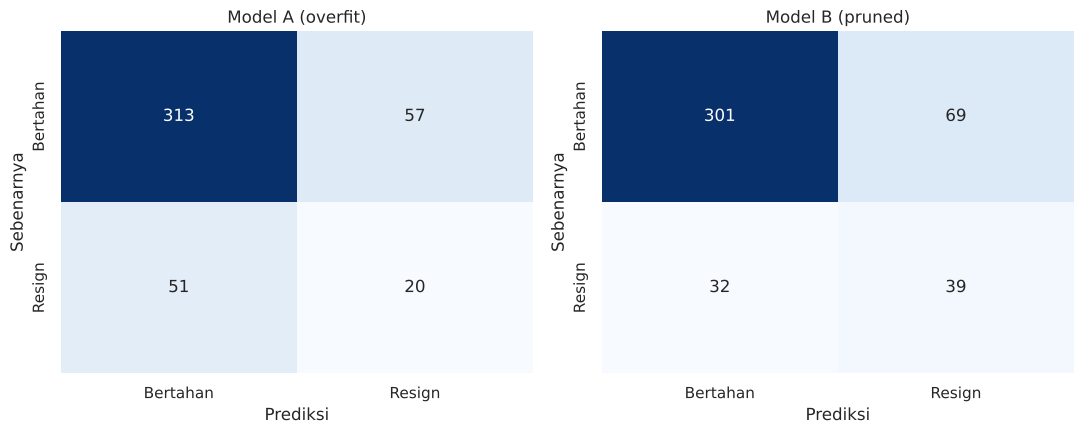

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (title, r) in zip(axes, [("Model A (overfit)", res_a), ("Model B (pruned)", res_b)]):
    sns.heatmap(r["cm"], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=LABELS, yticklabels=LABELS)
    ax.set_title(title)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Sebenarnya")
plt.tight_layout()
plt.savefig(IMG_DIR / "confusion_matrix.png", dpi=150)
plt.show()

**Interpretasi:** pada Model B jumlah *False Negative* (karyawan resign yang terlewat) lebih kecil dibanding Model A, sebagai ganti *False Positive* yang lebih banyak.

### 8.2 Pohon keputusan Model B

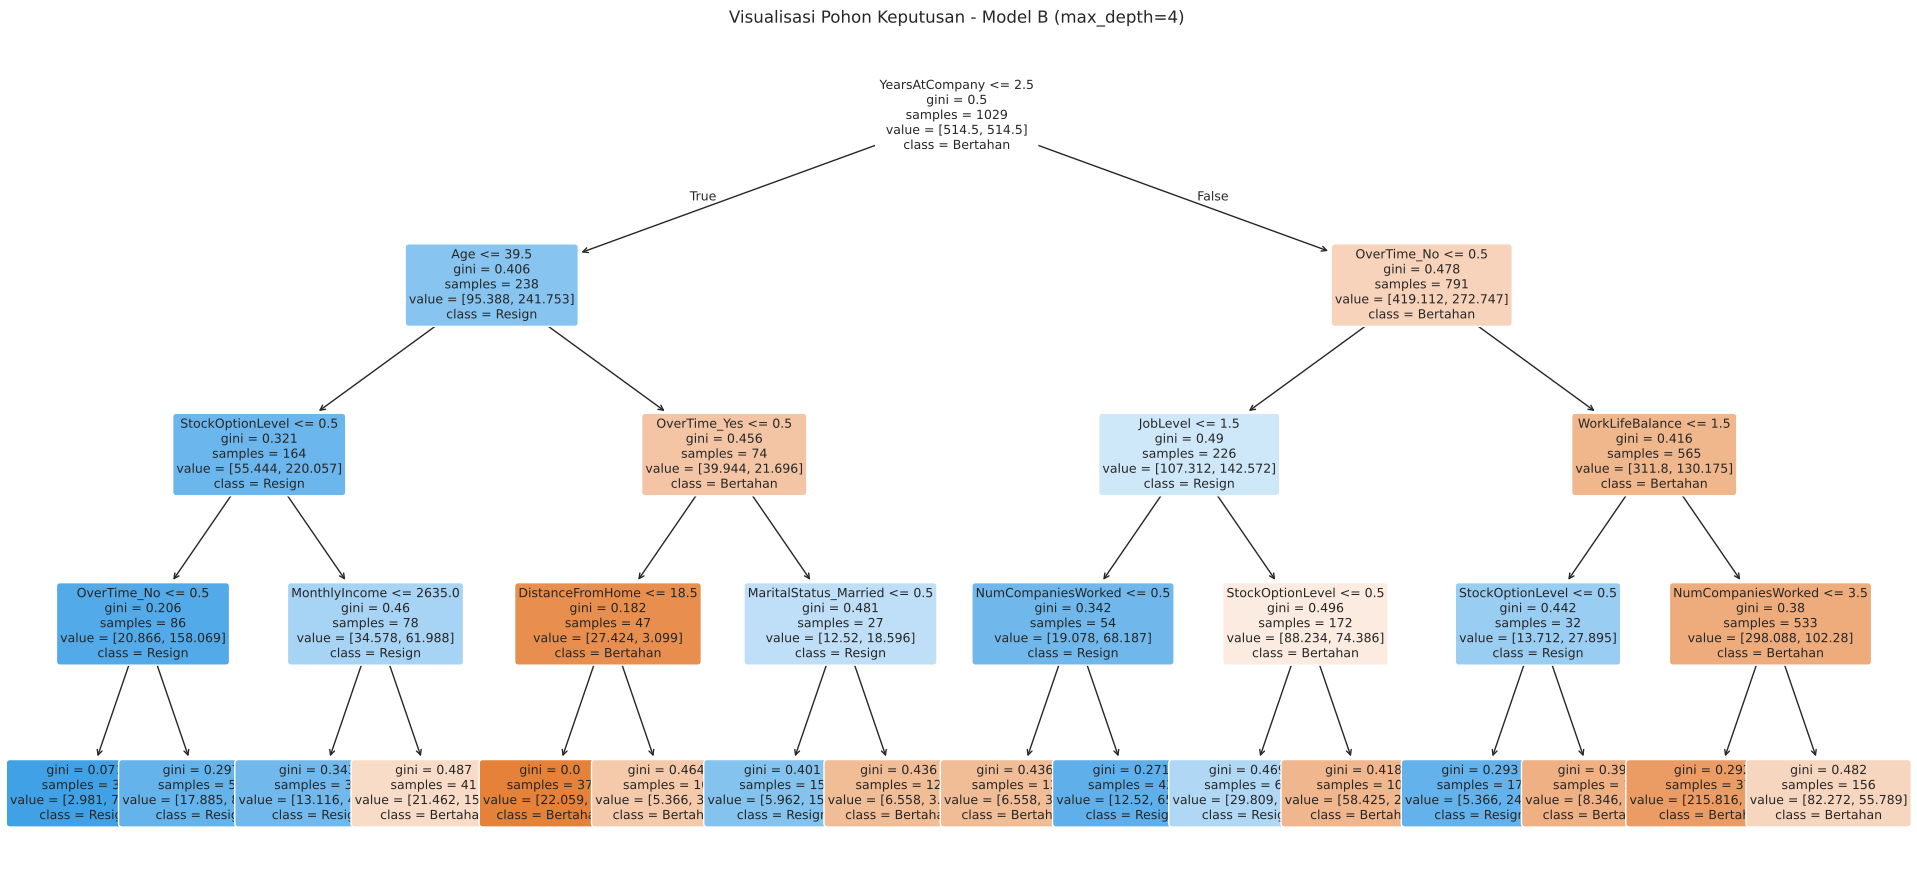

In [13]:
plt.figure(figsize=(24, 11))
plot_tree(model_b, feature_names=X.columns, class_names=LABELS,
          filled=True, rounded=True, fontsize=9)
plt.title("Visualisasi Pohon Keputusan - Model B (max_depth=4)")
plt.savefig(IMG_DIR / "decision_tree_b.png", dpi=130, bbox_inches="tight")
plt.show()

### 8.3 Aturan jika-maka dari pohon

In [14]:
rules = export_text(model_b, feature_names=list(X.columns))
(MODEL_DIR / "rules_model_b.txt").write_text(rules, encoding="utf-8")
print(rules)

|--- YearsAtCompany <= 2.50
|   |--- Age <= 39.50
|   |   |--- StockOptionLevel <= 0.50
|   |   |   |--- OverTime_No <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- OverTime_No >  0.50
|   |   |   |   |--- class: 1
|   |   |--- StockOptionLevel >  0.50
|   |   |   |--- MonthlyIncome <= 2635.00
|   |   |   |   |--- class: 1
|   |   |   |--- MonthlyIncome >  2635.00
|   |   |   |   |--- class: 0
|   |--- Age >  39.50
|   |   |--- OverTime_Yes <= 0.50
|   |   |   |--- DistanceFromHome <= 18.50
|   |   |   |   |--- class: 0
|   |   |   |--- DistanceFromHome >  18.50
|   |   |   |   |--- class: 0
|   |   |--- OverTime_Yes >  0.50
|   |   |   |--- MaritalStatus_Married <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- MaritalStatus_Married >  0.50
|   |   |   |   |--- class: 0
|--- YearsAtCompany >  2.50
|   |--- OverTime_No <= 0.50
|   |   |--- JobLevel <= 1.50
|   |   |   |--- NumCompaniesWorked <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- NumCompaniesWorked >  0.50
|

**Contoh interpretasi jalur (dari akar ke daun):**

1. **Jika** lama di perusahaan ≤ 2,5 tahun **dan** usia ≤ 39,5 **dan** tidak punya opsi saham, **maka** prediksi **Resign**. Karyawan muda yang baru bergabung tanpa opsi saham paling rentan keluar.
2. **Jika** lama di perusahaan > 2,5 tahun **dan** lembur **dan** level jabatan > 1 **dan** punya opsi saham, **maka** prediksi **Bertahan**. Karyawan senior yang lembur tetap bertahan bila mendapat opsi saham.
3. **Jika** lama di perusahaan > 2,5 tahun **dan** tidak lembur **dan** keseimbangan kerja-hidup rendah (≤ 1,5) **dan** tanpa opsi saham, **maka** prediksi **Resign**. Walau tidak lembur, keseimbangan kerja-hidup yang buruk tanpa insentif saham mendorong resign.

*Catatan: tiga jalur ini sudah dicocokkan dengan teks aturan di atas. Bila Anda mengubah parameter atau fitur, baca ulang aturan dan sesuaikan jalurnya.*

### 8.4 Feature importance

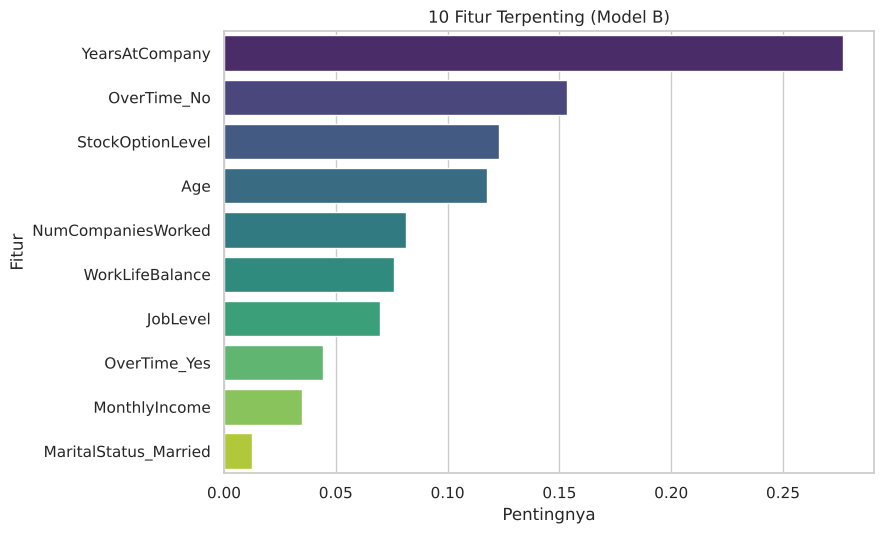

,Fitur,Pentingnya
4,YearsAtCompany,0.276846
11,OverTime_No,0.153359
10,StockOptionLevel,0.123193
0,Age,0.117811
6,NumCompaniesWorked,0.081520
9,WorkLifeBalance,0.076050
3,JobLevel,0.069838
12,OverTime_Yes,0.044437
1,MonthlyIncome,0.034772
14,MaritalStatus_Married,0.012564


In [15]:
imp = (pd.DataFrame({"Fitur": X.columns, "Pentingnya": model_b.feature_importances_})
       .sort_values("Pentingnya", ascending=False))
top = imp.head(10)

plt.figure(figsize=(9, 5.5))
sns.barplot(x="Pentingnya", y="Fitur", data=top, hue="Fitur", palette="viridis", legend=False)
plt.title("10 Fitur Terpenting (Model B)")
plt.tight_layout()
plt.savefig(IMG_DIR / "feature_importance.png", dpi=150)
plt.show()
top

**Interpretasi:** `YearsAtCompany` (lama bekerja) paling berpengaruh, diikuti `OverTime`, `StockOptionLevel`, dan `Age`. Fitur-fitur ini yang paling sering dipakai pohon untuk memisahkan karyawan yang resign dan bertahan.

### 8.5 Kurva ROC

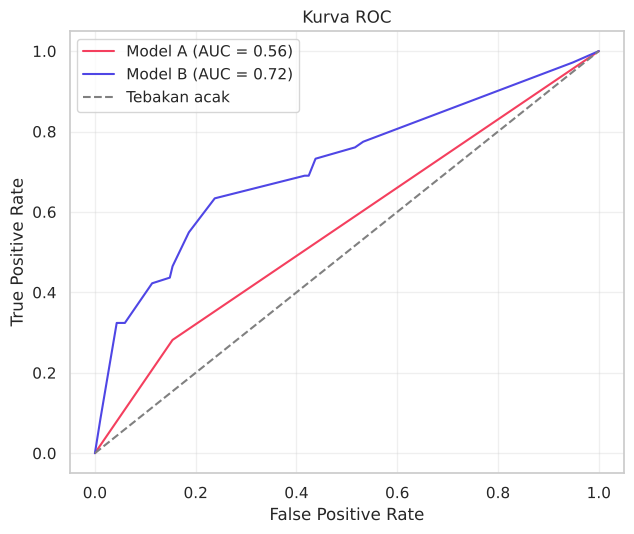

In [16]:
plt.figure(figsize=(6.5, 5.5))
for title, r, col in [("Model A", res_a, "#f43f5e"), ("Model B", res_b, "#4f46e5")]:
    fpr, tpr, _ = roc_curve(y_test, r["proba"])
    plt.plot(fpr, tpr, color=col, label=f"{title} (AUC = {r['auc']:.2f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Tebakan acak")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Kurva ROC")
plt.legend()
plt.grid(alpha=.3)
plt.tight_layout()
plt.savefig(IMG_DIR / "roc_curve.png", dpi=150)
plt.show()

## 9. Menyimpan Model dan Metrik untuk Aplikasi Flask
Model B dipilih dan disimpan dengan **Joblib** bersama daftar kolom (agar urutan fitur pada prediksi web sama dengan saat pelatihan). Metrik disimpan sebagai JSON untuk ditampilkan di halaman web.

> Setiap kali parameter atau fitur diubah, jalankan ulang notebook dari atas agar file ini diperbarui.

In [17]:
joblib.dump({"model": model_b, "columns": list(X.columns)}, MODEL_DIR / "attrition_model.joblib")

metrics = {
    "n_rows": int(len(df)),
    "n_features": int(X.shape[1]),
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "class_no": int(counts["No"]),
    "class_yes": int(counts["Yes"]),
    "A": {k: v for k, v in res_a.items() if k != "proba"},
    "B": {k: v for k, v in res_b.items() if k != "proba"},
    "importances": [{"fitur": r.Fitur, "nilai": round(float(r.Pentingnya), 4)} for r in top.itertuples()],
}
(MODEL_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")

print("Tersimpan:")
for p in [MODEL_DIR / "attrition_model.joblib", MODEL_DIR / "metrics.json", MODEL_DIR / "rules_model_b.txt"] + sorted(IMG_DIR.glob("*.png")):
    print(" -", p.relative_to(BASE), f"({p.stat().st_size / 1024:.0f} KB)")

Tersimpan:
 - model/attrition_model.joblib (5 KB)
 - model/metrics.json (1 KB)
 - model/rules_model_b.txt (2 KB)
 - static/img/confusion_matrix.png (57 KB)
 - static/img/decision_tree_b.png (432 KB)
 - static/img/feature_importance.png (68 KB)
 - static/img/roc_curve.png (87 KB)
 - static/img/target_distribution.png (36 KB)


### Uji cepat: model yang disimpan bisa dimuat dan dipakai memprediksi

In [18]:
bundle = joblib.load(MODEL_DIR / "attrition_model.joblib")
contoh = pd.DataFrame([{
    "Age": 25, "MonthlyIncome": 2200, "DistanceFromHome": 20, "JobLevel": 1, "YearsAtCompany": 1,
    "TotalWorkingYears": 2, "NumCompaniesWorked": 3, "JobSatisfaction": 1,
    "EnvironmentSatisfaction": 2, "WorkLifeBalance": 1, "StockOptionLevel": 0,
    "OverTime": "Yes", "MaritalStatus": "Single", "BusinessTravel": "Travel_Frequently"}])
contoh = pd.get_dummies(contoh, columns=CAT_COLS, dtype=int).reindex(columns=bundle["columns"], fill_value=0)
p = bundle["model"].predict_proba(contoh)[0][1]
print(f"Probabilitas resign: {p*100:.1f}% -> {'RESIGN' if p >= 0.5 else 'BERTAHAN'}")

Probabilitas resign: 96.3% -> RESIGN


## 10. Kesimpulan

1. **Overfitting terbukti:** Model A mencapai akurasi latih 100% tetapi akurasi uji jauh lebih rendah. Pruning pada Model B mengurangi kesenjangan itu.
2. **Interpretasi:** pohon keputusan Model B bisa dibaca sebagai aturan jika-maka. Lama bekerja, lembur, opsi saham, dan usia menjadi penentu utama.
3. **Data tidak seimbang:** hanya sekitar 16% karyawan resign, sehingga recall kelas Resign lebih penting daripada akurasi. Model B dengan `class_weight="balanced"` meningkatkan recall tetapi menurunkan precision.
4. **Keterbatasan:** dataset bersifat fiktif dan hasil prediksi hanya pendukung diskusi, bukan keputusan final terhadap karyawan.
5. **Langkah berikutnya:** model B (`model/attrition_model.joblib`) dimuat oleh `app.py` pada aplikasi web Flask.

## Referensi
- Dokumentasi scikit-learn `DecisionTreeClassifier`: https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
- Dokumentasi scikit-learn `plot_tree`: https://scikit-learn.org/stable/modules/generated/sklearn.tree.plot_tree.html
- Dataset: https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset